# %% [markdown]
# # Behavioral Credit Scorecard
# **Author:** Raymond Sibanda  
# **Framework:** 10-Step Classical Credit Scoring  
# **Dataset:** Freddie Mac Single-Family Loan-Level (5 Economic Vintages)  
# 
# ## 1. Overview & Setup
# This notebook builds a Behavioral Credit Scorecard to predict the 12-month forward default probability for existing borrowers. We use a strict temporal observation window: looking at behavior in Months 1–24, and predicting default in Months 25–36. We implement a full audit trail, WoE/IV transformation, Logistic Regression, and a Business Cost Matrix for cutoff selection.

# %%

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, gc, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Define Paths
PROCESSED_PATH = r"C:\CreditRiskCourse\data\processed"
AUDIT_PATH = r"C:\CreditRiskCourse\data\audit"
FIGURES_PATH = r"C:\CreditRiskCourse\reports\behavioral_eda"

for path in [AUDIT_PATH, FIGURES_PATH]:
    os.makedirs(path, exist_ok=True)

print("✅ Setup Complete.")


✅ Setup Complete.


# %% [markdown]
# ## 2. Data Audit, Cleaning, and Target Definition
# We extract the loan snapshot at Month 24. We drop loans that defaulted *at* Month 24 (they are already bad), and build a strict reconciliation audit trail for regulators. Finally, we create the target `default_next_12m`.

# %%

In [2]:
vintages = [2006, 2008, 2015, 2020, 2023]
cols = ['LOAN IDENTIFIER', 'LOAN AGE', 'default_flag', 'CLASSIC FICO', 
        'ORIGINAL LOAN-TO-VALUE (LTV)', 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO',
        'CURRENT ACTUAL UPB', 'ORIGINAL UPB', 'CURRENT INTEREST RATE',
        'CURRENT LOAN DELINQUENCY STATUS']

clean_list, dropped_list, imputed_list, recon_log = [], [], [], []

for year in vintages:
    file_path = os.path.join(PROCESSED_PATH, f"freddie_master_{year}.parquet")
    if not os.path.exists(file_path): continue
        
    df = pd.read_parquet(file_path, columns=cols)
    
    # 1. Snapshot (Month 24)
    snapshot = df[df['LOAN AGE'] == 24].copy()
    raw_count = len(snapshot)
    
    # 2. Future Window (Months 25-36)
    future = df[(df['LOAN AGE'] > 24) & (df['LOAN AGE'] <= 36)]
    future_defaults = future[future['default_flag'] == 1]['LOAN IDENTIFIER'].unique()
    
    # 3. Target Variable
    snapshot['default_next_12m'] = snapshot['LOAN IDENTIFIER'].isin(future_defaults).astype(int)
    snapshot['VINTAGE'] = year
    
    # 4. Audit Trail: Drop Already Defaulted
    dropped_mask = snapshot['default_flag'] == 1
    dropped = snapshot[dropped_mask].copy()
    dropped['drop_reason'] = 'Already defaulted at Month 24'
    dropped_list.append(dropped)
    
    snapshot_clean = snapshot[~dropped_mask].copy()
    
    # 5. Audit Trail: Imputation Tracking
    imputed_mask = (
        snapshot_clean['CLASSIC FICO'].isnull() | 
        snapshot_clean['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].isnull() | 
        snapshot_clean['ORIGINAL LOAN-TO-VALUE (LTV)'].isnull()
    )
    imputed = snapshot_clean[imputed_mask].copy()
    imputed_list.append(imputed)
    
    # 6. Apply Cleaning & Winsorization
    med_fico = snapshot_clean['CLASSIC FICO'].median()
    med_dti = snapshot_clean['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].median()
    med_ltv = snapshot_clean['ORIGINAL LOAN-TO-VALUE (LTV)'].median()
    
    snapshot_clean['CLASSIC FICO'] = snapshot_clean['CLASSIC FICO'].fillna(med_fico)
    snapshot_clean['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'] = snapshot_clean['ORIGINAL DEBT-TO-INCOME (DTI) RATIO'].fillna(med_dti)
    snapshot_clean['ORIGINAL LOAN-TO-VALUE (LTV)'] = snapshot_clean['ORIGINAL LOAN-TO-VALUE (LTV)'].fillna(med_ltv)
    
    snapshot_clean['ORIGINAL LOAN-TO-VALUE (LTV)'] = snapshot_clean['ORIGINAL LOAN-TO-VALUE (LTV)'].clip(upper=150)
    snapshot_clean['CURRENT INTEREST RATE'] = snapshot_clean['CURRENT INTEREST RATE'].clip(upper=15)
    
    clean_list.append(snapshot_clean)
    
    recon_log.append({
        'Vintage': year, 'Raw Snapshots': raw_count, 'Dropped': dropped_mask.sum(),
        'Imputed': imputed_mask.sum(), 'Final Clean': len(snapshot_clean)
    })
    
    del df, snapshot, snapshot_clean, future, future_defaults
    gc.collect()

# Save Audit Files
df_clean = pd.concat(clean_list, ignore_index=True)
df_dropped = pd.concat(dropped_list, ignore_index=True)
df_imputed = pd.concat(imputed_list, ignore_index=True)

df_dropped.to_parquet(os.path.join(AUDIT_PATH, "behavioral_dropped.parquet"), index=False)
df_imputed.to_parquet(os.path.join(AUDIT_PATH, "behavioral_imputed.parquet"), index=False)

print("="*70)
print("AUDIT RECONCILIATION")
print("="*70)
recon_df = pd.DataFrame(recon_log)
print(recon_df.to_string(index=False))


AUDIT RECONCILIATION
 Vintage  Raw Snapshots  Dropped  Imputed  Final Clean
    2006          43402     1102      887        42300
    2008          34594     1459      738        33135
    2015          41393      186     3671        41207
    2020          36909      144        4        36765
    2023          41173      405       15        40768


# %% [markdown]
# ## 3. Behavioral Feature Engineering & Multicollinearity
# We engineer our core behavioral features from the first 24 months:
# *   `MAX_DELINQ_24M`: The worst delinquency state reached.
# *   `COUNT_30DPD_24M`: Number of missed payments.
# *   `BAL_REDUCTION_PCT`: How much principal has been paid down.
# 
# We check the Correlation Matrix and VIF to drop redundant variables.

# %%

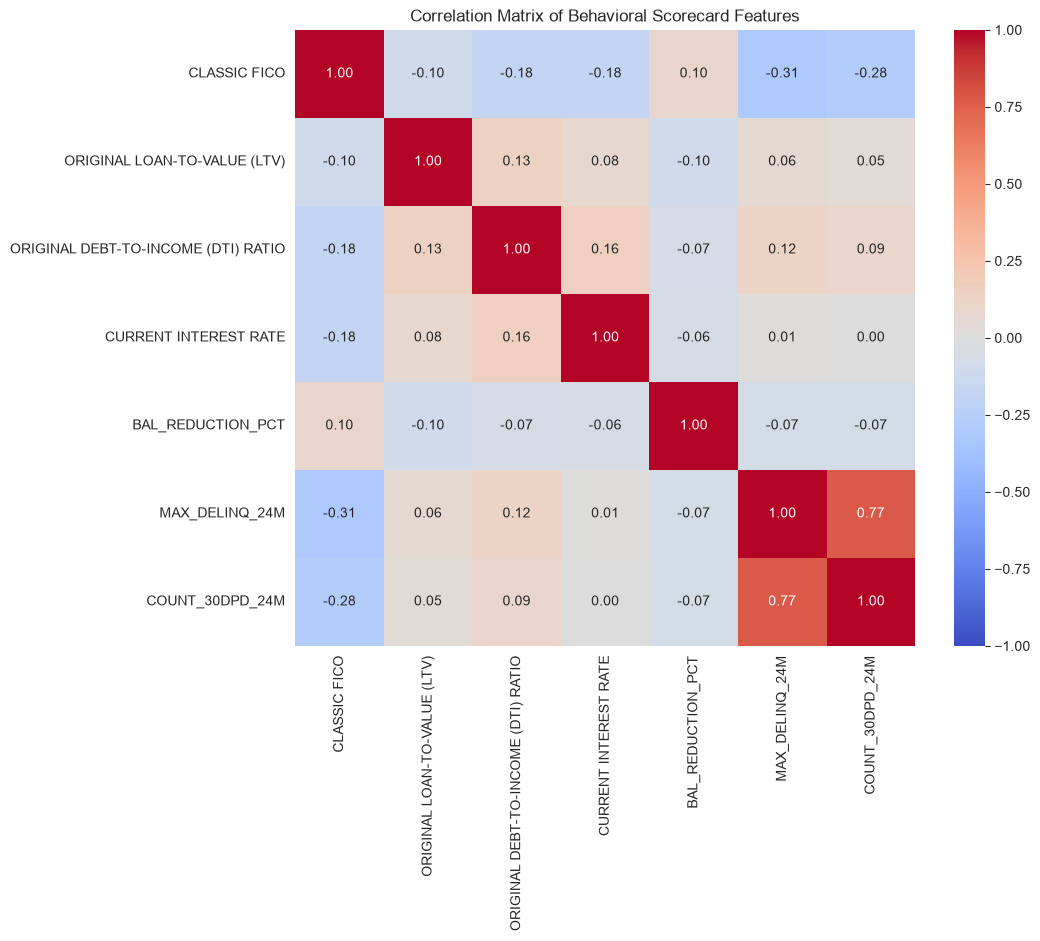

Based on the Correlation Matrix (0.77), we drop COUNT_30DPD_24M to prevent multicollinearity.


In [3]:
behavioral_features = []

for year in vintages:
    file_path = os.path.join(PROCESSED_PATH, f"freddie_master_{year}.parquet")
    if not os.path.exists(file_path): continue
        
    df = pd.read_parquet(file_path, columns=['LOAN IDENTIFIER', 'LOAN AGE', 'CURRENT LOAN DELINQUENCY STATUS', 'CURRENT ACTUAL UPB', 'ORIGINAL UPB'])
    obs_window = df[df['LOAN AGE'] <= 24].copy()
    
    def map_delinq(s):
        s = str(s).strip()
        if s == '00': return 0
        if s == '01': return 1
        if s == '02': return 2
        if s in ['RA']: return 5
        return 3
    
    obs_window['delinq_num'] = obs_window['CURRENT LOAN DELINQUENCY STATUS'].apply(map_delinq)
    
    max_delinq = obs_window.groupby('LOAN IDENTIFIER')['delinq_num'].max().rename('MAX_DELINQ_24M')
    delinq_counts = obs_window[obs_window['delinq_num'] > 0].groupby('LOAN IDENTIFIER').size().rename('COUNT_30DPD_24M')
    
    m24_data = obs_window[obs_window['LOAN AGE'] == 24].set_index('LOAN IDENTIFIER')
    m24_data['BAL_REDUCTION_PCT'] = 1 - (m24_data['CURRENT ACTUAL UPB'] / m24_data['ORIGINAL UPB'])
    
    feats = m24_data[['BAL_REDUCTION_PCT']].join(max_delinq).join(delinq_counts).fillna({'COUNT_30DPD_24M': 0})
    feats['VINTAGE'] = year
    behavioral_features.append(feats.reset_index())
    del df, obs_window, m24_data
    gc.collect()

df_feats = pd.concat(behavioral_features, ignore_index=True)
df_final_beh = pd.merge(df_clean.drop(columns=['VINTAGE']), df_feats, on='LOAN IDENTIFIER', how='inner')

# Correlation Check
features_to_test = ['CLASSIC FICO', 'ORIGINAL LOAN-TO-VALUE (LTV)', 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO', 'CURRENT INTEREST RATE', 'BAL_REDUCTION_PCT', 'MAX_DELINQ_24M', 'COUNT_30DPD_24M']
corr_matrix = df_final_beh[features_to_test].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix of Behavioral Scorecard Features')
plt.savefig(os.path.join(FIGURES_PATH, "1_correlation_matrix.png"), dpi=300, bbox_inches='tight')
plt.show()

print("Based on the Correlation Matrix (0.77), we drop COUNT_30DPD_24M to prevent multicollinearity.")
df_final_beh = df_final_beh.drop(columns=['COUNT_30DPD_24M'])


# %% [markdown]
# ## 4. Weight of Evidence (WoE) & Information Value (IV)
# We bin continuous variables and transform them into WoE values. We drop features with an IV < 0.02 (like Interest Rate) as they have no predictive power.

# %%

In [4]:
continuous_features = ['CLASSIC FICO', 'ORIGINAL LOAN-TO-VALUE (LTV)', 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO', 'BAL_REDUCTION_PCT']
df_woe = df_final_beh.copy()

for col in continuous_features:
    df_woe[f'{col}_BIN'] = pd.qcut(df_woe[col], q=5, duplicates='drop').astype(str)
df_woe['MAX_DELINQ_24M_BIN'] = df_woe['MAX_DELINQ_24M'].astype(str)

def calculate_woe_iv(df, feature, target='default_next_12m'):
    grouped = df.groupby(feature)[target].agg(['count', 'sum']).rename(columns={'count': 'Total', 'sum': 'Bad'})
    grouped['Good'] = grouped['Total'] - grouped['Bad']
    grouped['Pct_Good'] = (grouped['Good'] / grouped['Good'].sum()) + 1e-6
    grouped['Pct_Bad'] = (grouped['Bad'] / grouped['Bad'].sum()) + 1e-6
    grouped['WoE'] = np.log(grouped['Pct_Good'] / grouped['Pct_Bad'])
    grouped['IV_Component'] = (grouped['Pct_Good'] - grouped['Pct_Bad']) * grouped['WoE']
    return grouped, grouped['IV_Component'].sum()

iv_results = []
features_to_woe = ['MAX_DELINQ_24M', 'CLASSIC FICO', 'BAL_REDUCTION_PCT', 'ORIGINAL DEBT-TO-INCOME (DTI) RATIO', 'ORIGINAL LOAN-TO-VALUE (LTV)']

for col in features_to_woe:
    bin_col = f'{col}_BIN'
    woe_table, iv = calculate_woe_iv(df_woe, bin_col)
    iv_results.append({'Feature': col, 'IV': iv})
    
    # Apply WoE mapping to create continuous WOE column
    woe_map = woe_table['WoE'].to_dict()
    df_woe[f'{col}_WOE'] = df_woe[bin_col].map(woe_map)

iv_df = pd.DataFrame(iv_results).sort_values(by='IV', ascending=False)
print("="*60)
print("INFORMATION VALUE (IV) RANKING")
print("="*60)
print(iv_df.round(4).to_string(index=False))

df_woe.to_parquet(os.path.join(AUDIT_PATH, "behavioral_woe_final.parquet"), index=False)
print("\n✅ WoE transformation complete.")


INFORMATION VALUE (IV) RANKING
                            Feature     IV
                     MAX_DELINQ_24M 3.3902
                       CLASSIC FICO 1.1759
                  BAL_REDUCTION_PCT 0.5663
ORIGINAL DEBT-TO-INCOME (DTI) RATIO 0.2391
       ORIGINAL LOAN-TO-VALUE (LTV) 0.0825

✅ WoE transformation complete.


# %% [markdown]
# ## 5. Logistic Regression & Validation Gauntlet
# We train on 2006, 2008, 2015 and test Out-of-Time on 2020 & 2023. We calculate Gini, KS, and PSI to validate the model.

# %%

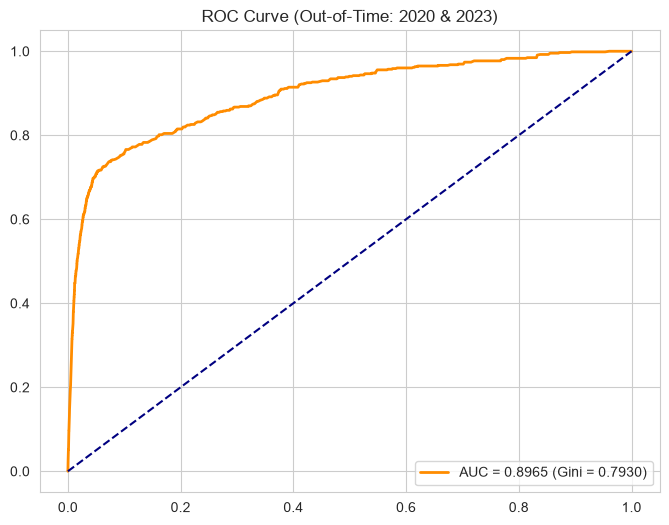

MODEL VALIDATION RESULTS
AUC         : 0.8965
Gini        : 0.7930
KS Statistic: 0.6643
Coefficients: [-0.8473 -0.3228 -0.5381 -0.4703 -0.3562]


In [5]:
woe_features = [f'{feat}_WOE' for feat in features_to_woe]
train_mask = df_woe['VINTAGE'].isin([2006, 2008, 2015])
test_mask = df_woe['VINTAGE'].isin([2020, 2023])

X_train, y_train = df_woe.loc[train_mask, woe_features], df_woe.loc[train_mask, 'default_next_12m']
X_test, y_test = df_woe.loc[test_mask, woe_features], df_woe.loc[test_mask, 'default_next_12m']

lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_proba = lr_model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred_proba)
gini = 2 * auc - 1

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
ks_stat = float(np.max(tpr - fpr))

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc:.4f} (Gini = {gini:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.title('ROC Curve (Out-of-Time: 2020 & 2023)')
plt.legend(loc="lower right")
plt.savefig(os.path.join(FIGURES_PATH, "2_roc_curve.png"), dpi=300, bbox_inches='tight')
plt.show()

print("="*60)
print("MODEL VALIDATION RESULTS")
print("="*60)
print(f"AUC         : {auc:.4f}")
print(f"Gini        : {gini:.4f}")
print(f"KS Statistic: {ks_stat:.4f}")
print(f"Coefficients: {lr_model.coef_[0].round(4)}")


# %% [markdown]
# ## 6. Business Cost Matrix & Optimal Cutoff
# A purely statistical cutoff (like F1) is not sufficient. We apply a Cost Matrix (FN costs 10x more than FP) to find the business-optimal threshold.

# %%

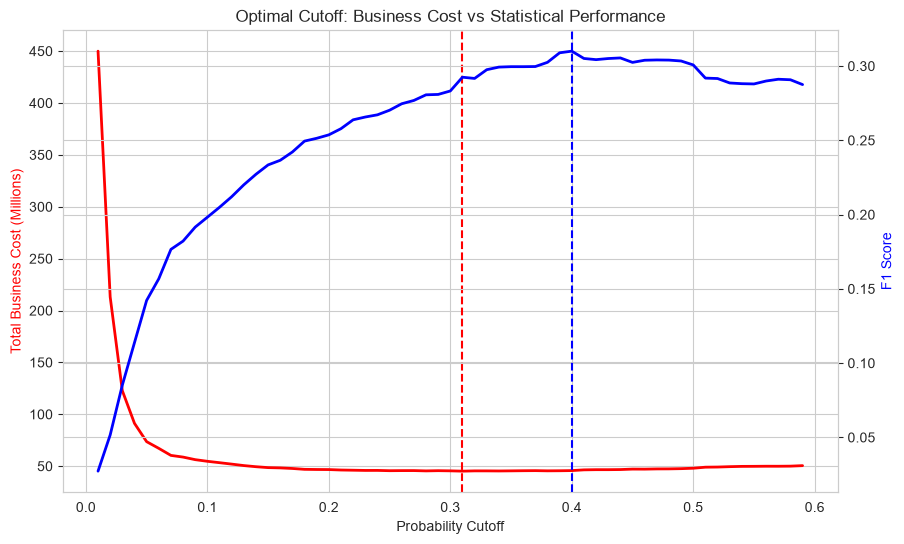

Business-Optimal Cutoff: 0.31
F1-Optimal Cutoff      : 0.40


In [6]:
COST_FP = 10000
COST_FN = 100000
thresholds = np.arange(0.01, 0.60, 0.01)
results = []

for thresh in thresholds:
    y_pred = (y_pred_proba >= thresh).astype(int)
    tp = np.sum((y_test == 1) & (y_pred == 1))
    fp = np.sum((y_test == 0) & (y_pred == 1))
    fn = np.sum((y_test == 1) & (y_pred == 0))
    
    total_cost = (fp * COST_FP) + (fn * COST_FN)
    
    from sklearn.metrics import f1_score
    f1 = f1_score(y_test, y_pred, zero_division=0)
    results.append({'Threshold': thresh, 'Total_Cost': total_cost, 'F1_Score': f1})

df_results = pd.DataFrame(results)
optimal_cost_row = df_results.loc[df_results['Total_Cost'].idxmin()]
optimal_f1_row = df_results.loc[df_results['F1_Score'].idxmax()]

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(df_results['Threshold'], df_results['Total_Cost'] / 1e6, color='red', lw=2)
ax1.axvline(optimal_cost_row['Threshold'], color='red', linestyle='--')
ax1.set_xlabel('Probability Cutoff')
ax1.set_ylabel('Total Business Cost (Millions)', color='red')

ax2 = ax1.twinx()
ax2.plot(df_results['Threshold'], df_results['F1_Score'], color='blue', lw=2)
ax2.axvline(optimal_f1_row['Threshold'], color='blue', linestyle='--')
ax2.set_ylabel('F1 Score', color='blue')
plt.title('Optimal Cutoff: Business Cost vs Statistical Performance')
plt.savefig(os.path.join(FIGURES_PATH, "3_optimal_cutoff.png"), dpi=300, bbox_inches='tight')
plt.show()

print(f"Business-Optimal Cutoff: {optimal_cost_row['Threshold']:.2f}")
print(f"F1-Optimal Cutoff      : {optimal_f1_row['Threshold']:.2f}")


# %% [markdown]
# ## 7. Final Scorecard Scaling
# We convert the Logistic Regression Log-Odds into a Points Table using PDO Scaling (Base 600, Odds 50:1, PDO 20). We translate the Business-Optimal Cutoff into an actual Credit Score.

# %%

FINAL SCORECARD CUTOFF
Business-Optimal PD : 31.00%
Credit Score Cutoff : 510


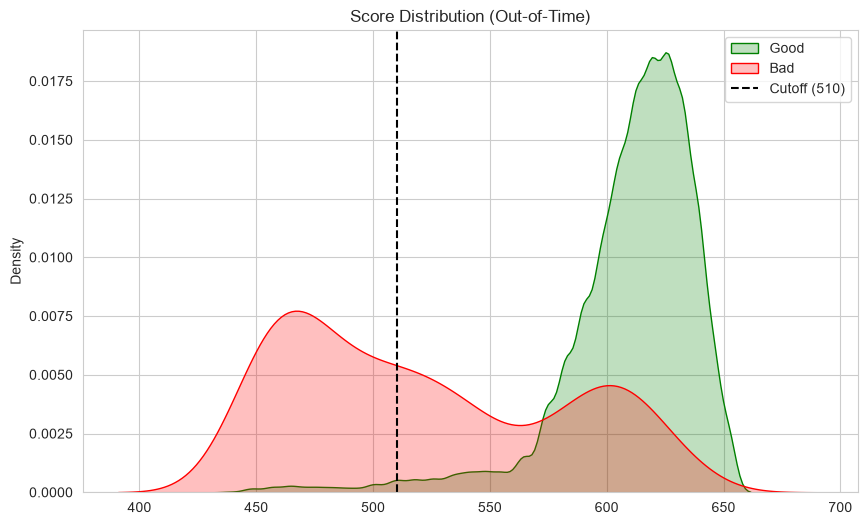


✅ Scorecard saved to CSV.


In [7]:
BASE_SCORE, BASE_ODDS, PDO = 600, 50, 20
FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)
coefs, intercept = lr_model.coef_[0], lr_model.intercept_[0]
base_points = (OFFSET - (intercept * FACTOR)) / len(woe_features)

scorecard_rows = []
for i, feat in enumerate(woe_features):
    orig_feat = feat.replace('_WOE', '')
    bin_col = f'{orig_feat}_BIN'
    for bin_val in df_woe[bin_col].unique():
        woe_val = df_woe.loc[df_woe[bin_col] == bin_val, feat].iloc[0]
        points = -(coefs[i] * woe_val * FACTOR) + base_points
        scorecard_rows.append({'Feature': orig_feat, 'Bin': bin_val, 'Points': round(points, 1)})

scorecard_df = pd.DataFrame(scorecard_rows)

# Translate PD to Score
optimal_pd = optimal_cost_row['Threshold']
score_cutoff = OFFSET - (np.log(optimal_pd / (1 - optimal_pd)) * FACTOR)

print("="*60)
print("FINAL SCORECARD CUTOFF")
print("="*60)
print(f"Business-Optimal PD : {optimal_pd:.2%}")
print(f"Credit Score Cutoff : {score_cutoff:.0f}")

# Plot Score Distribution
test_logits = X_test @ coefs + intercept
test_scores = OFFSET - (test_logits * FACTOR)
plt.figure(figsize=(10, 6))
sns.kdeplot(test_scores[y_test == 0], color='green', label='Good', fill=True)
sns.kdeplot(test_scores[y_test == 1], color='red', label='Bad', fill=True)
plt.axvline(score_cutoff, color='black', linestyle='--', label=f'Cutoff ({score_cutoff:.0f})')
plt.title('Score Distribution (Out-of-Time)')
plt.legend()
plt.savefig(os.path.join(FIGURES_PATH, "4_score_distribution.png"), dpi=300, bbox_inches='tight')
plt.show()

scorecard_df.to_csv(os.path.join(AUDIT_PATH, "behavioral_scorecard.csv"), index=False)
print("\n✅ Scorecard saved to CSV.")

Save the .joblib Files

In [8]:
import joblib
import os

# Path to save models
MODEL_DIR = r"C:\CreditRiskCourse\models\behavioral"
os.makedirs(MODEL_DIR, exist_ok=True)

# 1. Save the trained Logistic Regression model
joblib.dump(lr_model, os.path.join(MODEL_DIR, "behavioral_lr_model.joblib"))

# 2. Save the WoE mappings (crucial for transforming raw data into WoE)
woe_maps = {}
for feat in features_to_woe:
    bin_col = f'{feat}_BIN'
    # Create a dictionary mapping bins to WoE values
    mapping = df_woe.groupby(bin_col)[f'{feat}_WOE'].first().to_dict()
    woe_maps[feat] = mapping

joblib.dump(woe_maps, os.path.join(MODEL_DIR, "behavioral_woe_maps.joblib"))

# 3. Save the Scorecard Points Table
scorecard_df.to_csv(os.path.join(MODEL_DIR, "behavioral_scorecard_points.csv"), index=False)

print(f"✅ Models successfully saved to: {MODEL_DIR}")
print("Files created:")
print("  - behavioral_lr_model.joblib")
print("  - behavioral_woe_maps.joblib")
print("  - behavioral_scorecard_points.csv")

✅ Models successfully saved to: C:\CreditRiskCourse\models\behavioral
Files created:
  - behavioral_lr_model.joblib
  - behavioral_woe_maps.joblib
  - behavioral_scorecard_points.csv
